## Image Descriptions with Gemini 

Generate detailed textual descriptions for extracted images using Gemini 2.5 Flash.

**Prerequisites:**
- Make sure you rag-data dir with extracted dir like markdown, images and tables
- Google API key set in .env file

**Output:**
- Markdown descriptions saved to `data/rag-data/images_desc/{company}/{document}/page_X.md`

### Setup and Imports

In [1]:
from dotenv import load_dotenv
load_dotenv()

from pathlib import Path
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage

from PIL import Image

import base64
import io

### Configuration

In [2]:
# Paths
IMAGES_DIR = "data/rag-data/images"
OUTPUT_DESC_DIR = "data/rag-data/images_desc"

# Model configuration
MODEL_NAME = "gemini-2.5-flash"

model = ChatGoogleGenerativeAI(model=MODEL_NAME)

### Description Generation Function

In [3]:
describe_image_prompt = """Analyze this financial document page and extract meaningful data in a concise format.

For charts and graphs:
- Identify the metric being measured
- List key data points and values
- Note significant trends (growth, decline, stability)

For tables:
- Extract column headers and key rows
- Note important values and totals

For text:
- Summarize key facts and numbers only
- Skip formatting, headers, and navigation elements

Be direct and factual. Focus on numbers, trends, and insights that would be useful for retrieval."""

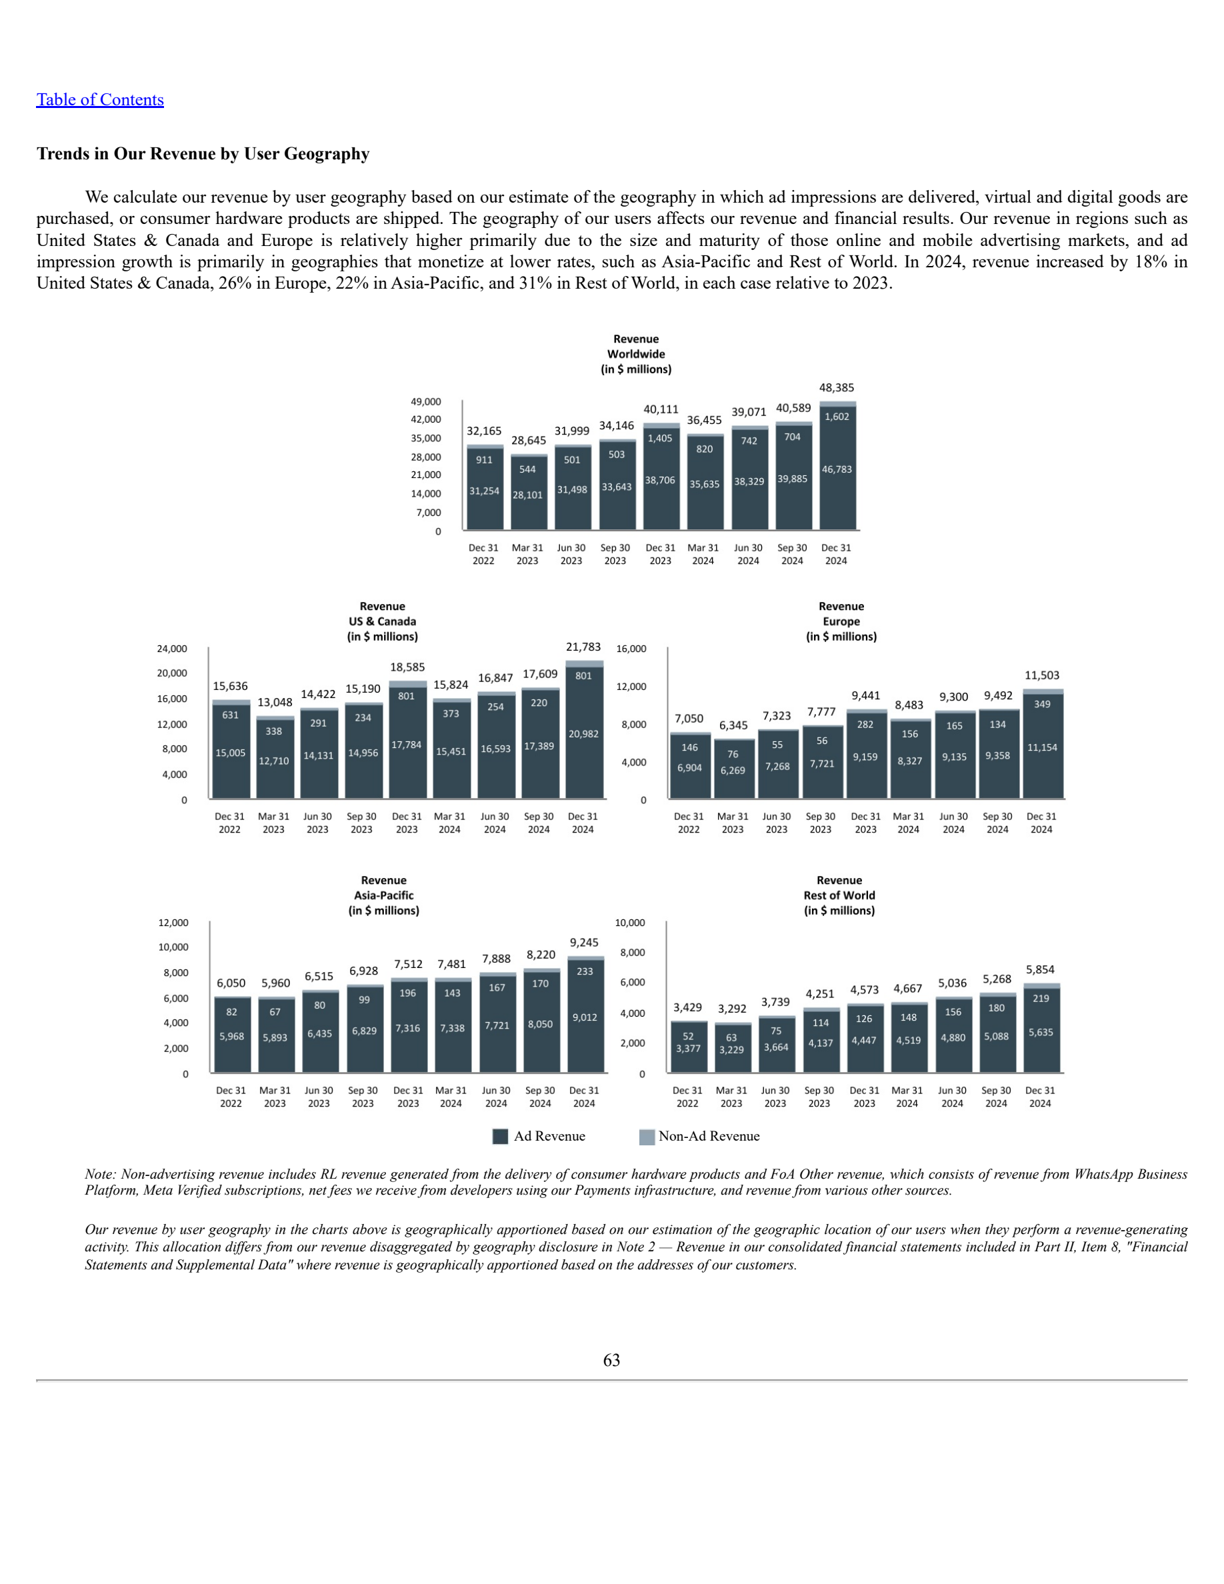

In [5]:
image_path = Path(r'data\rag-data\images\meta\meta 10-k 2024\page_64.png')
image = Image.open(image_path)
image

In [6]:
from langchain.messages import SystemMessage


def generate_image_description(image_path: Path):
    image = Image.open(image_path)
    buffered = io.BytesIO()
    image.save(buffered, format='PNG')

    image_base64 = base64.b64encode(buffered.getvalue()).decode()

    message = HumanMessage(
        content=[
            {'type': 'text', 'text': describe_image_prompt},
            {'type': 'image_url', 'image_url': f"data:image/png;base64,{image_base64}"}
        ]
    )
    system_prompt = SystemMessage('You are an AI Assistant')

    response = model.invoke([system_prompt, message])

    return response.text

In [7]:
image_path = Path(r'data\rag-data\images\meta\meta 10-k 2024\page_64.png')

response = generate_image_description(image_path)

In [8]:
print(response
      )

**Text Summary:**
Revenue is calculated based on user geography (ad impressions, virtual/digital goods, consumer hardware). US & Canada and Europe show relatively lower growth due to market maturity, while Asia-Pacific and Rest of World have higher growth potential. In 2024, revenue increased by 18% in United States & Canada, 22% in Europe, 22% in Asia-Pacific, and 31% in Rest of World, all relative to 2023. Non-advertising revenue includes consumer hardware, WhatsApp Business Platform, Meta Verified subscriptions, and developer payments.

**Charts Analysis:**

**Revenue Worldwide (in $ millions)**
*   **Metric:** Total Revenue, split into Ad Revenue and Non-Ad Revenue.
*   **Key Data Points (Total Revenue, Ad Revenue, Non-Ad Revenue):**
    *   Dec 31 2022: 32,165 (31,254, 911)
    *   Mar 31 2023: 28,645 (28,101, 544)
    *   Jun 30 2023: 31,999 (31,498, 501)
    *   Sep 30 2023: 34,146 (33,643, 503)
    *   Dec 31 2023: 40,111 (38,706, 1,405)
    *   Mar 31 2024: 36,455 (35,635, 820

In [9]:
# print(response)

def generate_and_save_description(image_path: Path):
    company_name = image_path.parent.parent.name
    doc_name = image_path.parent.name

    output_dir = Path(OUTPUT_DESC_DIR)/company_name/doc_name
    output_dir.mkdir(parents=True, exist_ok=True)

    desc_file = output_dir / f"{image_path.stem}.md"

    if desc_file.exists():
        return False
    
    description = generate_image_description(image_path)
    desc_file.write_text(description, encoding='utf-8')
    
    return True

In [24]:
image_path = Path(r'data\rag-data\images\meta\meta 10-k 2024\page_64.png')

response = generate_and_save_description(image_path)

In [29]:
from tqdm import tqdm

images_path = Path(IMAGES_DIR)
image_files = list(images_path.rglob("page_*.png"))

for image_path in tqdm(image_files):
    response = generate_and_save_description(image_path)


100%|██████████| 77/77 [15:34<00:00, 12.13s/it]
